In [ ]:
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

wine = load_wine()

X = wine.data
y = wine.target
features = pd.DataFrame(X, columns=wine.feature_names)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Original feature shape:", X.shape)
print("Standardized feature shape:", X_scaled.shape)
print(pd.DataFrame(X_scaled, columns=wine.feature_names).head())


Original feature shape: (178, 13)
Standardized feature shape: (178, 13)
    alcohol  malic_acid       ash  alcalinity_of_ash  magnesium  \
0  1.518613   -0.562250  0.232053          -1.169593   1.913905   
1  0.246290   -0.499413 -0.827996          -2.490847   0.018145   
2  0.196879    0.021231  1.109334          -0.268738   0.088358   
3  1.691550   -0.346811  0.487926          -0.809251   0.930918   
4  0.295700    0.227694  1.840403           0.451946   1.281985   

   total_phenols  flavanoids  nonflavanoid_phenols  proanthocyanins  \
0       0.808997    1.034819             -0.659563         1.224884   
1       0.568648    0.733629             -0.820719        -0.544721   
2       0.808997    1.215533             -0.498407         2.135968   
3       2.491446    1.466525             -0.981875         1.032155   
4       0.808997    0.663351              0.226796         0.401404   

   color_intensity       hue  od280/od315_of_diluted_wines   proline  
0         0.251717  0.36217

In [ ]:

k_values = range(2, 9)
inertias = []
silhouette_scores = []

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    
    cluster_labels = kmeans.fit_predict(X_scaled)
    
   
    inertias.append(kmeans.inertia_)
    
   
    score = silhouette_score(X_scaled, cluster_labels)
    silhouette_scores.append(score)


results = pd.DataFrame({
    "k": list(k_values),
    "Inertia": inertias,
    "Silhouette Score": silhouette_scores
})

print(results)


   k      Inertia  Silhouette Score
0  2  1658.758852          0.259317
1  3  1277.928489          0.284859
2  4  1175.428333          0.260170
3  5  1109.512739          0.201619
4  6  1046.002333          0.237167
5  7   981.595233          0.203628
6  8   935.201211          0.157014


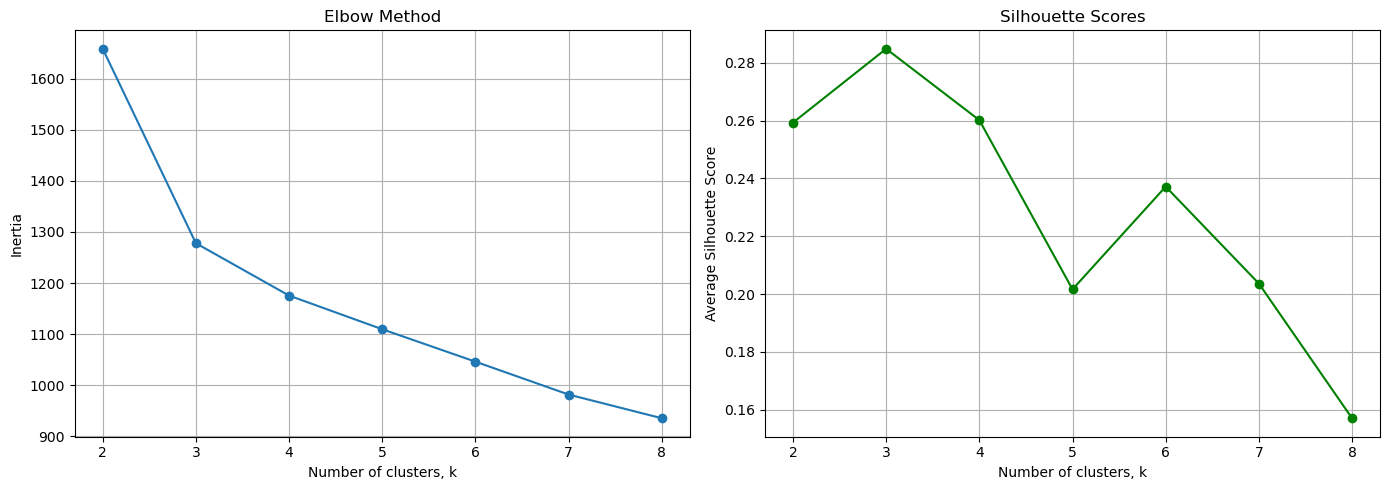

In [ ]:

fig, axes = plt.subplots(1, 2, figsize=(14, 5))


axes[0].plot(k_values, inertias, marker="o")
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Number of clusters, k")
axes[0].set_ylabel("Inertia")
axes[0].set_xticks(list(k_values))
axes[0].grid(True)

axes[1].plot(k_values, silhouette_scores, marker="o", color="green")
axes[1].set_title("Silhouette Scores")
axes[1].set_xlabel("Number of clusters, k")
axes[1].set_ylabel("Average Silhouette Score")
axes[1].set_xticks(list(k_values))
axes[1].grid(True)

plt.tight_layout()
plt.show()


In [4]:
best_k_silhouette = k_values[np.argmax(silhouette_scores)]

print("Best k according to the silhouette score:",
      best_k_silhouette)
print("Highest silhouette score:",
      max(silhouette_scores))


Best k according to the silhouette score: 3
Highest silhouette score: 0.2848589191898987


In [ ]:

kmeans_final = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

clusters = kmeans_final.fit_predict(X_scaled)


wine_clustered = pd.DataFrame(
    X,
    columns=wine.feature_names
)

wine_clustered["Cluster"] = clusters

print(wine_clustered.head())
print("\nCluster sizes:")
print(wine_clustered["Cluster"].value_counts().sort_index())


   alcohol  malic_acid   ash  alcalinity_of_ash  magnesium  total_phenols  \
0    14.23        1.71  2.43               15.6      127.0           2.80   
1    13.20        1.78  2.14               11.2      100.0           2.65   
2    13.16        2.36  2.67               18.6      101.0           2.80   
3    14.37        1.95  2.50               16.8      113.0           3.85   
4    13.24        2.59  2.87               21.0      118.0           2.80   

   flavanoids  nonflavanoid_phenols  proanthocyanins  color_intensity   hue  \
0        3.06                  0.28             2.29             5.64  1.04   
1        2.76                  0.26             1.28             4.38  1.05   
2        3.24                  0.30             2.81             5.68  1.03   
3        3.49                  0.24             2.18             7.80  0.86   
4        2.69                  0.39             1.82             4.32  1.04   

   od280/od315_of_diluted_wines  proline  Cluster  
0         

In [ ]:

selected_k = 3

kmeans_final = KMeans(
    n_clusters=selected_k,
    random_state=42,
    n_init=10
)

clusters = kmeans_final.fit_predict(X_scaled)

cluster_sizes = pd.Series(clusters).value_counts().sort_index()

print("Cluster sizes:")
for cluster, size in cluster_sizes.items():
    print(f"Cluster {cluster}: {size} wines")


Cluster sizes:
Cluster 0: 65 wines
Cluster 1: 51 wines
Cluster 2: 62 wines


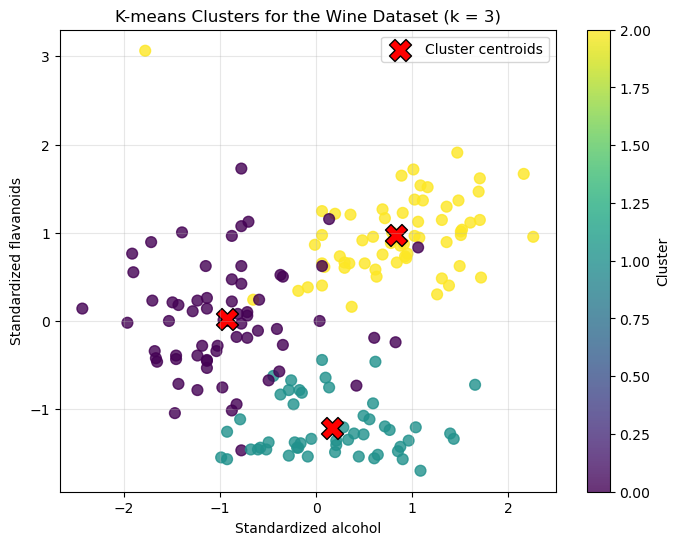

In [ ]:

feature_1 = "alcohol"
feature_2 = "flavanoids"

index_1 = wine.feature_names.index(feature_1)
index_2 = wine.feature_names.index(feature_2)

plt.figure(figsize=(8, 6))

scatter = plt.scatter(
    X_scaled[:, index_1],
    X_scaled[:, index_2],
    c=clusters,
    cmap="viridis",
    s=60,
    alpha=0.8
)

plt.scatter(
    kmeans_final.cluster_centers_[:, index_1],
    kmeans_final.cluster_centers_[:, index_2],
    marker="X",
    s=250,
    c="red",
    edgecolor="black",
    label="Cluster centroids"
)

plt.xlabel("Standardized alcohol")
plt.ylabel("Standardized flavanoids")
plt.title("K-means Clusters for the Wine Dataset (k = 3)")
plt.colorbar(scatter, label="Cluster")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


In [ ]:
from sklearn.metrics import adjusted_rand_score
import pandas as pd


cultivars = wine.target


contingency_table = pd.crosstab(
    pd.Series(clusters, name="Cluster"),
    pd.Series(cultivars, name="Cultivar")
)

print("Contingency table:")
print(contingency_table)


ari = adjusted_rand_score(cultivars, clusters)

print(f"\nAdjusted Rand Index: {ari:.3f}")


Contingency table:
Cultivar   0   1   2
Cluster             
0          0  65   0
1          0   3  48
2         59   3   0

Adjusted Rand Index: 0.897


In [ ]:
from sklearn.metrics import adjusted_rand_score
import pandas as pd


cultivars = wine.target


contingency_table = pd.crosstab(
    pd.Series(clusters, name="Cluster"),
    pd.Series(cultivars, name="Cultivar")
)

print("Contingency table:")
print(contingency_table)


ari = adjusted_rand_score(cultivars, clusters)

print(f"\nAdjusted Rand Index: {ari:.3f}")


Contingency table:
Cultivar   0   1   2
Cluster             
0          0  65   0
1          0   3  48
2         59   3   0

Adjusted Rand Index: 0.897
